# Task 1: Anti-cheat detection

รายงาน EDA จากข้อมูลในเครื่อง วันที่ 2 พฤศจิกายน 2026 ไม่มีการฝึกโมเดลใน notebook นี้ ค่าที่เขียนใน Markdown อิง snapshot ที่ตรวจครั้งนี้ หากเปลี่ยนข้อมูลให้สร้างรายงานใหม่และรันทุก cell อีกครั้ง

## 1. Task Overview

ทำนายผู้เล่นที่อาจโกง เพื่อจัดลำดับการตรวจสอบและลด false positive ต่อผู้เล่นปกติ

Target: `is_cheater`. 0=ผู้เล่นปกติ, 1=ผู้เล่นที่โกง

ไม่พบ metric ทางการในไฟล์ที่ได้รับ แนะนำ F1 และ ROC-AUC เป็น local proxy

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / 'sample_submission.csv').exists())
sys.path.insert(0, str(ROOT))
from shared.eda_utils import (
    TASKS, load_task, quality_table, outlier_table, bounds_table,
    association, strongest_pairs, period_changes, image_inventory, setup_plot,
)
setup_plot()

train, test, target, base = load_task(ROOT, 1)
frame = train if train is not None else test
features = frame.drop(columns=['player_id', target], errors='ignore')

## 2. Dataset Overview

| กลุ่ม | ความหมายตาม data card |
|---|---|
| performance | kill/death, headshot, accuracy และ win rate |
| timing/input | reaction time, input consistency, aiming และ movement |
| account/social | อายุบัญชี level friend network reports และ session |
| tactical | game sense, teamwork, map knowledge, utility และ crosshair |

In [2]:
overview = pd.DataFrame([
    {'split': name, 'rows': len(data), 'columns': data.shape[1],
     'target_available': int(data[target].notna().sum()) if target in data else 0}
    for name, data in [('train', train), ('test', test)] if data is not None
])
display(overview)
display(features.dtypes.astype(str).value_counts().rename('feature_count').to_frame())
with pd.option_context('display.max_rows', None):
    display(features.dtypes.astype(str).to_frame('dtype'))
display(frame.drop(columns='player_id').head(3))

,split,rows,columns,target_available
0,train,104000,33,90816
1,test,25889,32,0


,feature_count
float64,31


,dtype
kill_death_ratio,float64
headshot_percentage,float64
win_rate,float64
accuracy_score,float64
kill_consistency,float64
reaction_time_ms,float64
account_age_days,float64
level,float64
level_progression_speed,float64
friend_network_size,float64


,kill_death_ratio,headshot_percentage,win_rate,accuracy_score,kill_consistency,reaction_time_ms,...,first_blood_rate,survival_time_avg,damage_per_round,utility_usage_rate,crosshair_placement,is_cheater
0,5.1762,54.2455,85.6629,25.4578,0.7749,83.8281,...,0.4831,73.4760,55.7114,0.7906,0.8930,0.0000
1,6.5104,54.3886,99.1746,36.6796,0.8133,148.2957,...,NaN,NaN,NaN,0.7937,0.9568,0.0000
2,5.4572,60.4179,100.0000,44.5587,0.7209,117.6630,...,0.3358,40.7844,NaN,0.5636,0.8683,0.0000


**Findings & Interpretation**

**Findings:** Train มี 104,000 แถว; test มี 25,889 แถว, feature 31 ตัว และ label ที่ใช้ได้ 90,816 แถว

**Interpretation:** ต้องแยกความครบของ feature ออกจากความครบของ label

**ML Implications:** ไม่เติม target ที่หายและไม่ใช้ player_id เป็น predictor

**Recommended Action:** ตรวจ missing และขอบเขตข้อมูลก่อนเลือก preprocessing

## 3. Data Quality Analysis

Duplicate IDs: 0
Duplicate feature rows: 0
Train/test ID overlap: 0
Missing target: 13184


,dtype,missing,missing_pct,unique
survival_time_avg,float64,25305,24.3317,78695
weapon_switch_speed,float64,25213,24.2433,78787
avg_session_length_min,float64,23895,22.9760,80105
movement_pattern_score,float64,23324,22.4269,80676
friend_network_size,float64,23265,22.3702,350
reports_received,float64,23193,22.3010,26
aiming_smoothness,float64,21710,20.8750,75614
communication_rate,float64,21402,20.5788,82598
team_play_score,float64,20235,19.4567,83765
spray_control_score,float64,17428,16.7577,83181


,feature,expected_min,expected_max,outside_range
0,headshot_percentage,0,100.0000,0
1,win_rate,0,100.0000,0
2,accuracy_score,0,100.0000,0
3,night_play_ratio,0,1.0000,0
4,reaction_time_ms,0,inf,0
5,account_age_days,0,inf,0


,iqr_outliers,observed,outlier_pct
level_progression_speed,13384,95560,14.0059
kill_death_ratio,2484,93962,2.6436
reaction_time_ms,2356,95881,2.4572
reports_received,1715,80807,2.1223
headshot_percentage,1113,101187,1.0999
accuracy_score,695,103356,0.6724
aiming_smoothness,404,82290,0.4909
input_consistency_score,339,93841,0.3612


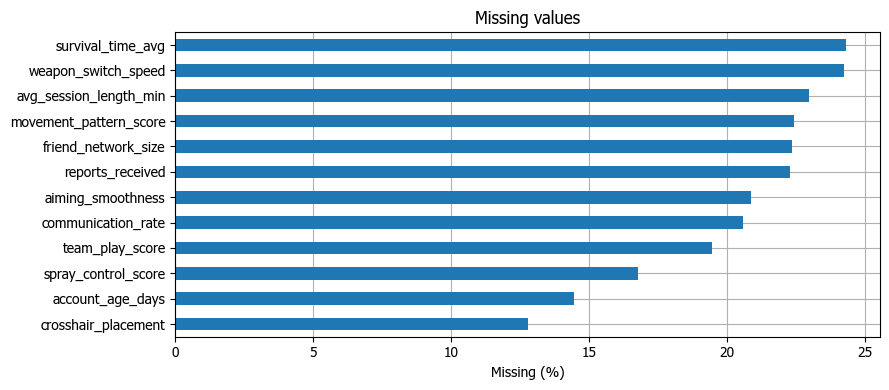

In [3]:
quality = quality_table(features)
display(quality.head(12))
print('Duplicate IDs:', int(frame.player_id.duplicated().sum()))
print('Duplicate feature rows:', int(features.duplicated().sum()))
if train is not None:
    print('Train/test ID overlap:', len(set(train.player_id) & set(test.player_id)))
    print('Missing target:', int(train[target].isna().sum()))
display(bounds_table(frame, 1))
display(outlier_table(features).head(8))
quality.missing_pct.head(12).sort_values().plot.barh(xlabel='Missing (%)', title='Missing values')
plt.tight_layout()
plt.show()

**Findings & Interpretation**

**Findings:** Feature missing เฉลี่ย 11.98%; สูงสุด `survival_time_avg` 24.33%; duplicate feature rows 0; พบค่าที่อยู่นอกช่วงตรวจทั้งหมด 0 จุด (นับระดับ cell); feature ที่มี IQR outlier สูงสุดคือ `level_progression_speed` 14.01%

**Interpretation:** ค่าหลุด IQR เป็น outlier เชิงสถิติ ไม่ยืนยันว่าเป็นข้อมูลผิด ช่วงที่ตรวจมาจากความหมายใน data card และอาจสะท้อนนิยามหรือข้อมูลสังเคราะห์ที่ต่างออกไป

**ML Implications:** ใช้โมเดลรองรับ missing หรือ fit imputer เฉพาะ training fold; ยังไม่ clip ทั้งชุด

**Recommended Action:** ตรวจ feature ที่อยู่นอกช่วงกับนิยามต้นทาง และเก็บ missing indicator เมื่อใช้ imputer

In [4]:
missing_compare = pd.DataFrame({'train_pct': features.isna().mean() * 100,
                                'test_pct': test[features.columns].isna().mean() * 100})
missing_compare['gap_pp'] = missing_compare.test_pct - missing_compare.train_pct
display(missing_compare.sort_values('gap_pp', key=lambda x: x.abs(), ascending=False).head(10))
print('Duplicate test feature rows:', test[features.columns].duplicated().sum())
train_hash = pd.util.hash_pandas_object(features, index=False)
test_hash = pd.util.hash_pandas_object(test[features.columns], index=False)
print('Train/test identical feature row hashes:', len(set(train_hash) & set(test_hash)))

Duplicate test feature rows: 0
Train/test identical feature row hashes: 0


,train_pct,test_pct,gap_pp
avg_session_length_min,22.9760,1.5760,-21.4000
aiming_smoothness,20.8750,2.0627,-18.8123
friend_network_size,22.3702,4.7395,-17.6307
account_age_days,14.4394,0.5562,-13.8832
movement_pattern_score,22.4269,8.7219,-13.7051
headshot_percentage,2.7048,14.1064,11.4016
team_play_score,19.4567,8.1270,-11.3297
survival_time_avg,24.3317,13.0557,-11.2760
spray_control_score,16.7577,5.5699,-11.1878
clutch_success_rate,2.4519,13.5347,11.0828


**Findings & Interpretation**

**Findings:** Missing ใน test เฉลี่ย 8.00%; ช่องว่าง train/test ที่มากสุดคือ `avg_session_length_min` 21.40 percentage points

**Interpretation:** การเปรียบเทียบนี้ตรวจเฉพาะ missingness และ exact feature rows ยังไม่พิสูจน์ว่าไม่มี distribution shift

**ML Implications:** ใช้ preprocessing ที่รองรับ missing ในทั้งสอง split และหลีกเลี่ยง fit บน test สำหรับ supervised tasks

**Recommended Action:** หากคะแนนจริงต่างจาก holdout มาก ให้ตรวจ feature distribution และรูปแบบเก็บข้อมูลเพิ่มเติม

## 4. Statistical Analysis

,count,mean,std,min,25%,50%,75%,max
kill_death_ratio,"93,962.0000",4.7380,1.5175,0.5000,3.7118,4.5667,5.5365,12.0000
headshot_percentage,"101,187.0000",47.8611,13.7531,5.0000,38.2705,47.1282,56.6538,95.0000
win_rate,"98,817.0000",71.3615,13.9955,16.3850,61.6723,71.1371,80.9961,100.0000
accuracy_score,"103,356.0000",40.1875,12.1194,8.0000,31.7073,39.6745,48.1115,85.0000
kill_consistency,"94,269.0000",0.6487,0.1504,0.2500,0.5436,0.6527,0.7561,0.9800
reaction_time_ms,"95,881.0000",135.1733,51.0955,55.0000,99.5538,128.4309,162.4762,714.4455
account_age_days,"88,983.0000",495.2540,350.9348,1.0054,156.2222,479.8771,762.0910,"1,499.6499"
level,"96,586.0000",62.8659,20.7432,25.0057,44.9050,62.8623,80.7726,99.9988
level_progression_speed,"95,560.0000",0.3646,1.5951,0.0029,0.0406,0.0813,0.2140,80.0287
friend_network_size,"80,735.0000",137.7670,84.6050,0.0000,64.0000,135.0000,206.0000,349.0000


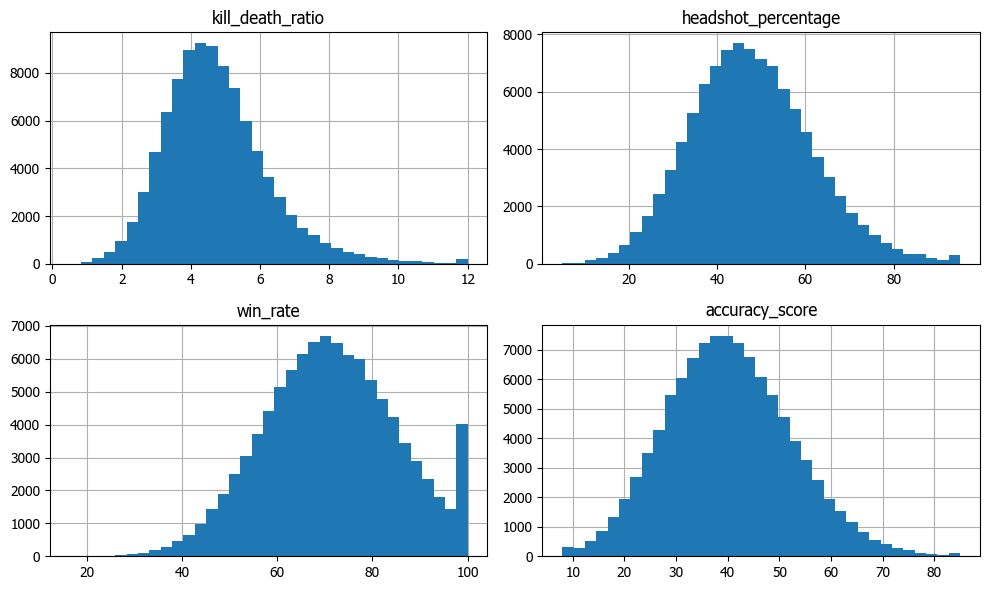

In [5]:
display(features.describe(include='all').T.head(12))
features[['kill_death_ratio', 'headshot_percentage', 'win_rate', 'accuracy_score']].hist(bins=35, figsize=(10, 6))
plt.tight_layout()
plt.show()

**Findings & Interpretation**

**Findings:** ข้อมูลตัวเลขมี 31 feature; `kill_death_ratio` median=4.567, p99=9.501; `headshot_percentage` median=47.128, p99=84.224; `win_rate` median=71.137, p99=100.000; `accuracy_score` median=39.675, p99=70.488

**Interpretation:** ช่วงและรูปทรงของ feature ต่างกัน จึงต้องอ่านแกนและหน่วยก่อนเปรียบเทียบ

**ML Implications:** Tree baseline ไม่ต้อง scale; หากเปลี่ยนเป็น linear/distance model ให้ scale ภายใน fold

**Recommended Action:** ตรวจ target และความสัมพันธ์กับ feature เพิ่มเพื่อเลือกการแปลงข้อมูล

,count,pct
is_cheater,,
0.0000,59091,56.8183
1.0000,31725,30.5048
NaN,13184,12.6769


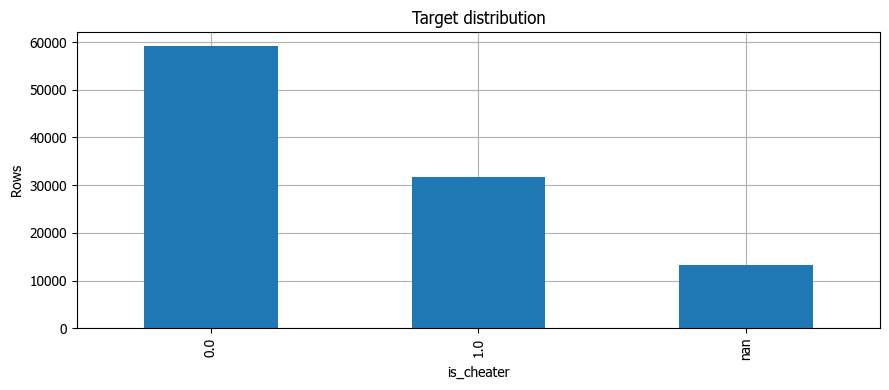

In [6]:
if target == 'spending_30d':
    display(frame[target].describe(percentiles=[.5, .9, .95, .99]).to_frame())
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    frame[target].hist(bins=50, ax=axes[0])
    axes[0].set_title('Spending (THB)')
    np.log1p(frame[target]).hist(bins=50, ax=axes[1])
    axes[1].set_title('log1p spending')
else:
    counts = frame[target].value_counts(dropna=False).sort_index()
    display(pd.DataFrame({'count': counts, 'pct': counts / len(frame) * 100}))
    counts.plot.bar(title='Target distribution', ylabel='Rows')
plt.tight_layout()
plt.show()

**Findings & Interpretation**

**Findings:** จำนวน label แต่ละคลาสคือ {0.0: 59091, 1.0: 31725}; target หาย 13,184 แถว

**Interpretation:** คลาสมีจำนวนไม่เท่ากัน ต้องระวัง accuracy ที่กลบผลของคลาสเล็ก

**ML Implications:** ใช้ stratified validation และตรวจ F1 รายคลาส; class weight ต้องประเมินจาก validation

**Recommended Action:** ใช้เฉพาะ label ที่สังเกตได้และรายงาน metric หลายมุม

## 5. Feature Relationships

,eta_squared
reports_received,0.1134
crosshair_placement,0.0519
kill_death_ratio,0.0181
headshot_percentage,0.0176
game_sense_score,0.0157
account_age_days,0.0097
accuracy_score,0.0079
level,0.0067
spray_control_score,0.0059
friend_network_size,0.0050


pearson_r
account_age_days        friend_network_size         0.5984
aiming_smoothness       spray_control_score         0.3525
reaction_time_ms        aiming_smoothness          -0.3438
                        input_consistency_score    -0.3015
account_age_days        level_progression_speed    -0.2505
reaction_time_ms        spray_control_score        -0.2468
level_progression_speed friend_network_size        -0.2329
kill_death_ratio        headshot_percentage         0.1863
account_age_days        reports_received           -0.1731
friend_network_size     reports_received           -0.1617

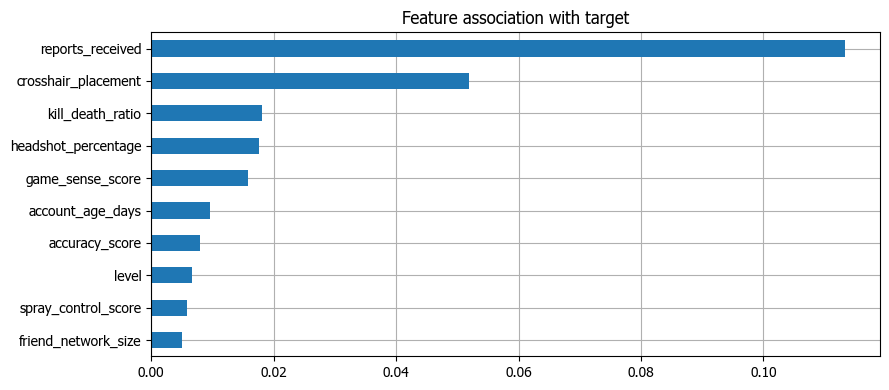

In [7]:
relevance = association(frame, target, regression=False)
display(relevance.head(12).rename('abs_spearman' if target == 'spending_30d' else 'eta_squared').to_frame())
display(strongest_pairs(features).rename('pearson_r').to_frame())
relevance.head(10).sort_values().plot.barh(title='Feature association with target')
plt.tight_layout()
plt.show()

**Findings & Interpretation**

**Findings:** Feature ที่มี association สูงสุดคือ `reports_received` = 0.1134 (eta squared; ไม่สมมติลำดับคลาส); คู่ feature ที่มี |Pearson r| สูงสุดคือ ('account_age_days', 'friend_network_size') r=0.5984

**Interpretation:** ความสัมพันธ์คำนวณบนคู่ที่ไม่ missing ไม่ได้แสดงเหตุและผลหรือยืนยัน leakage

**ML Implications:** หลีกเลี่ยงใช้ correlation ของรหัส multiclass เป็นตัวชี้วัดหลัก; ยังไม่เลือก feature ด้วย validation ชุดสุดท้าย

**Recommended Action:** ตรวจ class-conditional patterns และเวลาที่ feature ถูกสร้างก่อน target

### Feature interactions

In [8]:
interaction_data = frame.assign(
    reaction_bin=pd.qcut(frame.reaction_time_ms, 4, duplicates='drop'),
    headshot_bin=pd.qcut(frame.headshot_percentage, 4, duplicates='drop'),
)
interaction = interaction_data.pivot_table(index='reaction_bin', columns='headshot_bin',
                                          values=target, aggfunc='mean', observed=True)
display(interaction)
display(interaction_data.dropna(subset=[target]).groupby(
    ['reaction_bin', 'headshot_bin'], observed=True).size().unstack())

headshot_bin,"(4.999, 38.271]","(38.271, 47.128]","(47.128, 56.654]","(56.654, 95.0]"
reaction_bin,,,,
"(54.999, 99.554]",0.4163,0.3420,0.3187,0.2459
"(99.554, 128.431]",0.4249,0.3673,0.3310,0.2589
"(128.431, 162.476]",0.4343,0.3699,0.3292,0.2790
"(162.476, 714.446]",0.4447,0.3833,0.3594,0.2887


headshot_bin,"(4.999, 38.271]","(38.271, 47.128]","(47.128, 56.654]","(56.654, 95.0]"
reaction_bin,,,,
"(54.999, 99.554]",4862,5003,5140,5356
"(99.554, 128.431]",4834,5116,5115,5250
"(128.431, 162.476]",5135,5029,5057,5107
"(162.476, 714.446]",5536,5202,5072,4565


**Findings & Interpretation**

**Findings:** ตาราง interaction มี 4×4 ช่อง; ค่าที่สังเกตได้ต่ำสุด 0.2459, สูงสุด 0.4447

**Interpretation:** อัตรา cheater ในแต่ละช่องคำนวณจาก label ที่ทราบค่า ไม่ใช่ probability ที่โมเดลทำนาย; ช่วง bin มาจาก quartile ของข้อมูลที่ใช้วิเคราะห์ และบางช่องอาจมีตัวอย่างน้อย

**ML Implications:** Tree model รองรับความสัมพันธ์ร่วมแบบนี้ได้; ยังไม่สร้างกฎตัดสินจาก EDA เพียงอย่างเดียว

**Recommended Action:** อ่านจำนวนตัวอย่างในแต่ละช่องก่อนตีความ และตรวจผลบน validation แยกจาก EDA

## 6. Task-Specific EDA

In [9]:
display(frame.groupby(target)[['reaction_time_ms', 'headshot_percentage', 'reports_received', 'kill_death_ratio']].median())
missing_by_label = features.isna().mean(axis=1).groupby(frame[target]).mean()
display(missing_by_label.rename('mean_missing_fraction').to_frame())
display(frame.groupby(frame[target].isna())[['reaction_time_ms', 'headshot_percentage', 'reports_received', 'kill_death_ratio']].median())

,reaction_time_ms,headshot_percentage,reports_received,kill_death_ratio
is_cheater,,,,
0.0000,127.2673,48.4587,14.0000,4.7096
1.0000,130.5851,44.7753,10.0000,4.3133


,mean_missing_fraction
is_cheater,
0.0000,0.1195
1.0000,0.1200


,reaction_time_ms,headshot_percentage,reports_received,kill_death_ratio
is_cheater,,,,
False,128.4740,47.1362,12.0000,4.5688
True,128.0906,47.0614,12.0000,4.5504


**Findings & Interpretation**

**Findings:** Median reaction time: class 0=127.27 ms, class 1=130.59 ms; headshot: class 0=48.46, class 1=44.78

**Interpretation:** เป็นการเปรียบเทียบกลุ่มที่มี label; ไม่ควรสรุปว่าบัญชีที่ไม่มี label ปกติหรือโกง

**ML Implications:** ฝึก supervised เฉพาะ known label และตรวจ false positive ที่พฤติกรรมคล้ายผู้เล่นเก่ง

**Recommended Action:** แยก unlabeled rows ไว้ ไม่ใช้ pseudo-label ใน baseline รอบแรก

## 7. EDA Findings & Insights

- Feature missing เฉลี่ย 11.98% และมีค่าที่อยู่นอกช่วงตรวจ 0 จุด
- Duplicate feature rows 0 แถว
- Train มี target ที่ทราบค่า 90,816 จาก 104,000 แถว
- ความสัมพันธ์เป็น observed association; leakage และสาเหตุของค่าผิดช่วงยังเป็นประเด็นที่ต้องตรวจ

## 8. Preprocessing Recommendations

- ไม่ใช้ player_id เป็น predictor และไม่เติม target ที่หาย
- Fit imputer/encoder เฉพาะ training fold; HistGradientBoosting รองรับ NaN ใน numerical features
- ยังไม่ลบ IQR outlier อัตโนมัติ เพราะอาจเป็นกลุ่มพฤติกรรมที่ต้องการทำนาย
- Tree model ไม่จำเป็นต้อง scale; ถ้าใช้ linear/distance model ให้ scale ภายใน fold

## 9. Baseline Model Recommendations

เริ่ม HistGradientBoostingClassifier กับ known labels แบ่ง stratified holdout 80/20 seed 42 ตรวจ F1/ROC-AUC และ confusion matrix

การฝึกโมเดลอยู่ใน `02_baseline.ipynb` ไม่มีการ fit ใน EDA notebook นี้

## 10. Final EDA Summary

ยืนยันจากข้อมูลในเครื่อง: 104,000 แถวที่ใช้วิเคราะห์, 31 feature, missing เฉลี่ย 11.98% และ known labels 90,816 แถว

ขั้นถัดไปคือรัน baseline แยกจาก EDA ตรวจ prediction และเก็บ local validation ก่อนปรับโมเดลให้ยืนยัน metric ทางการ วิธีจับคู่แถว submission และ provenance ของ feature ยังไม่สามารถพิสูจน์ temporal leakage หรือสาเหตุที่ข้อมูลบางค่าหลุดช่วงจากไฟล์ปัจจุบันได้